## Function and derivatives

For `f(x) = x^3 - 3x^2 - 9x + 1`, the derivatives are `f'(x) = 3x^2 - 6x - 9` and `f''(x) = 6x - 6`. The critical x-values are `x = -1` and `x = 3`; the inflection x-value is `x = 1`. The panels share a sensible viewing interval, with vertical guides marking these x-values.

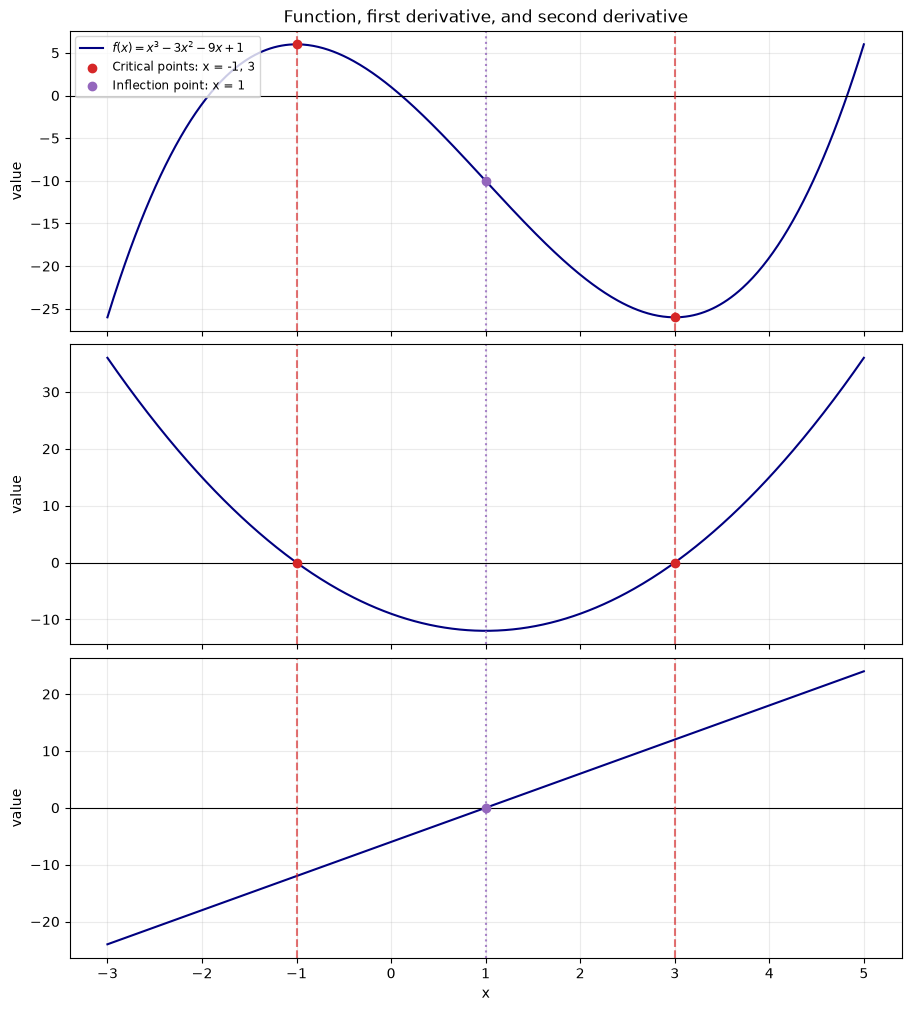

Critical points: (-1, 6) and (3, -26)
Inflection point: (1, -10)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return x**3 - 3*x**2 - 9*x + 1

def f_prime(x):
    return 3*x**2 - 6*x - 9

def f_double_prime(x):
    return 6*x - 6

x = np.linspace(-3, 5, 600)
critical_x = (-1, 3)
inflection_x = 1

fig, axes = plt.subplots(3, 1, figsize=(9, 10), sharex=True, constrained_layout=True)
curves = (
    (f(x), r"$f(x)=x^3-3x^2-9x+1$"),
    (f_prime(x), r"$f'(x)=3x^2-6x-9$"),
    (f_double_prime(x), r"$f''(x)=6x-6$"),
)

for ax, (y, label) in zip(axes, curves):
    ax.plot(x, y, color="navy", label=label)
    ax.axhline(0, color="black", linewidth=0.8)
    for critical in critical_x:
        ax.axvline(critical, color="tab:red", linestyle="--", alpha=0.65)
    ax.axvline(inflection_x, color="tab:purple", linestyle=":", alpha=0.8)
    ax.set_ylabel("value")
    ax.grid(True, alpha=0.25)

axes[0].scatter(critical_x, [f(value) for value in critical_x], color="tab:red", zorder=3,
                label="Critical points: x = -1, 3")
axes[0].scatter([inflection_x], [f(inflection_x)], color="tab:purple", zorder=3,
                label="Inflection point: x = 1")
axes[1].scatter(critical_x, [0, 0], color="tab:red", zorder=3)
axes[2].scatter([inflection_x], [0], color="tab:purple", zorder=3)
axes[0].set_title("Function, first derivative, and second derivative")
axes[0].legend(loc="upper left", fontsize="small")
axes[-1].set_xlabel("x")
axes[-1].set_xticks(np.arange(-3, 6, 1))
plt.show()

print(f"Critical points: ({critical_x[0]}, {f(critical_x[0])}) and ({critical_x[1]}, {f(critical_x[1])})")
print(f"Inflection point: ({inflection_x}, {f(inflection_x)})")

## Taylor approximations for `e^x` near 0

At `x = 0`, `e^x` and its first two derivatives all equal 1. Thus the first- and second-degree Taylor polynomials are `p1(x) = 1 + x` and `p2(x) = 1 + x + x^2/2`. The table compares their absolute errors with `e^x` at the requested points. The second-degree approximation is markedly more accurate, and both errors grow as the points move farther from 0.

| x | e^x | p1(x) = 1 + x | Absolute error, p1 | p2(x) = 1 + x + x^2/2 | Absolute error, p2 |
|---:|---:|---:|---:|---:|---:|
| -0.50 | 0.606530660 | 0.500000000 | 0.106530660 | 0.625000000 | 0.018469340 |
| -0.25 | 0.778800783 | 0.750000000 | 0.028800783 | 0.781250000 | 0.002449217 |
| -0.10 | 0.904837418 | 0.900000000 | 0.004837418 | 0.905000000 | 0.000162582 |
| +0.10 | 1.105170918 | 1.100000000 | 0.005170918 | 1.105000000 | 0.000170918 |
| +0.25 | 1.284025417 | 1.250000000 | 0.034025417 | 1.281250000 | 0.002775417 |
| +0.50 | 1.648721271 | 1.500000000 | 0.148721271 | 1.625000000 | 0.023721271 |

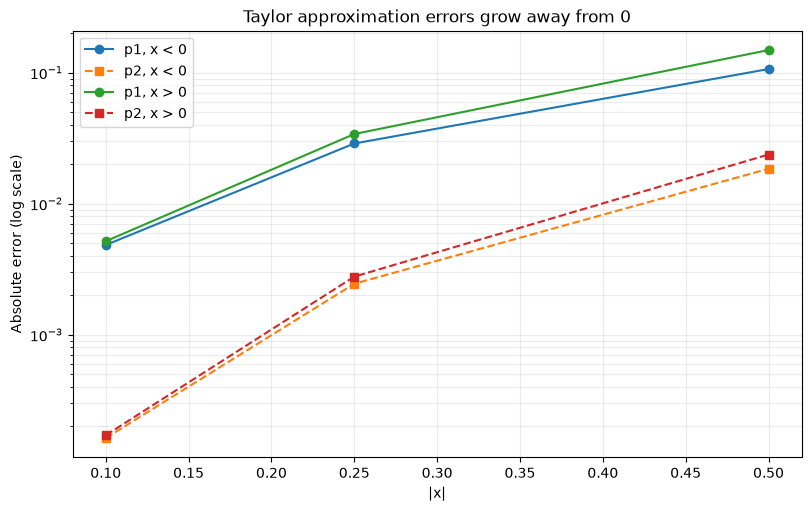

Largest absolute error ratio (p1 / p2): 30.3x


In [2]:
from IPython.display import Markdown, display

sample_x = np.array([-0.5, -0.25, -0.1, 0.1, 0.25, 0.5])
p1 = 1 + sample_x
p2 = 1 + sample_x + sample_x**2 / 2
exact = np.exp(sample_x)
error_p1 = np.abs(exact - p1)
error_p2 = np.abs(exact - p2)

table = [
    "| x | e^x | p1(x) = 1 + x | Absolute error, p1 | p2(x) = 1 + x + x^2/2 | Absolute error, p2 |",
    "|---:|---:|---:|---:|---:|---:|",
]
for i, value in enumerate(sample_x):
    table.append(
        f"| {value:+.2f} | {exact[i]:.9f} | {p1[i]:.9f} | {error_p1[i]:.9f} | "
        f"{p2[i]:.9f} | {error_p2[i]:.9f} |"
    )
display(Markdown("\n".join(table)))

distance = np.abs(sample_x)
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
for sign, label in ((-1, "x < 0"), (1, "x > 0")):
    mask = np.sign(sample_x) == sign
    order = np.argsort(distance[mask])
    ax.plot(distance[mask][order], error_p1[mask][order], "o-", label=f"p1, {label}")
    ax.plot(distance[mask][order], error_p2[mask][order], "s--", label=f"p2, {label}")
ax.set_yscale("log")
ax.set_xlabel("|x|")
ax.set_ylabel("Absolute error (log scale)")
ax.set_title("Taylor approximation errors grow away from 0")
ax.grid(True, which="both", alpha=0.25)
ax.legend()
plt.show()

assert np.all(error_p2 < error_p1), "p2 should be more accurate at every sample point."
print(f"Largest absolute error ratio (p1 / p2): {np.max(error_p1 / error_p2):.1f}x")

## Revenue optimization: analytic solution and grid search

For `R(q) = 120q - 0.5q^2` on `[0, 240]`, set `R'(q) = 120 - q` equal to zero. The critical point is `q = 120`, and because `R''(q) = -1 < 0`, it is a maximum. Check the interval endpoints as well. A grid search over the interval gives a numerical comparison.

Analytic optimum: q = 120, maximum revenue = 7200
Grid-search optimum: q = 120, maximum revenue = 7200


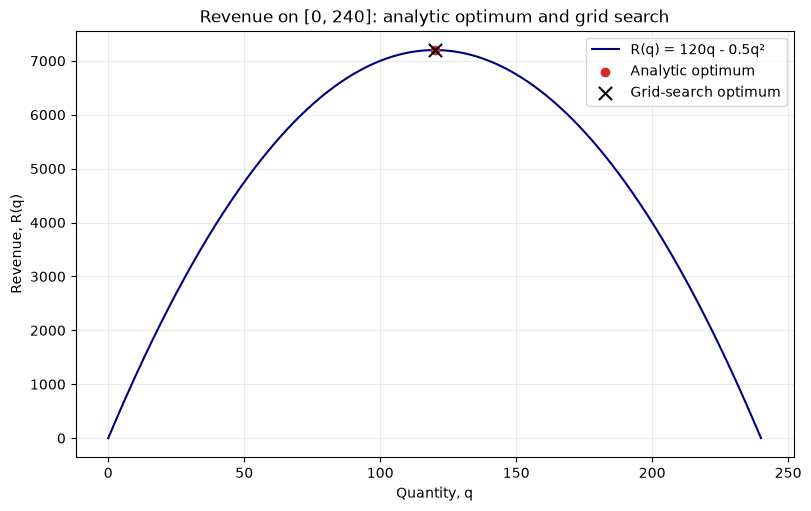

In [3]:
def revenue(q):
    return 120 * q - 0.5 * q**2

analytic_candidates = np.array([0, 120, 240])
analytic_revenues = revenue(analytic_candidates)
analytic_index = np.argmax(analytic_revenues)
analytic_q = analytic_candidates[analytic_index]
analytic_max_revenue = analytic_revenues[analytic_index]

grid_q = np.linspace(0, 240, 241)
grid_revenues = revenue(grid_q)
grid_index = np.argmax(grid_revenues)
grid_best_q = grid_q[grid_index]
grid_max_revenue = grid_revenues[grid_index]

print(f"Analytic optimum: q = {analytic_q:.0f}, maximum revenue = {analytic_max_revenue:.0f}")
print(f"Grid-search optimum: q = {grid_best_q:.0f}, maximum revenue = {grid_max_revenue:.0f}")
assert analytic_q == grid_best_q == 120
assert analytic_max_revenue == grid_max_revenue == 7200

q_curve = np.linspace(0, 240, 500)
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.plot(q_curve, revenue(q_curve), color="navy", label="R(q) = 120q - 0.5q²")
ax.scatter([analytic_q], [analytic_max_revenue], color="tab:red", zorder=3,
           label="Analytic optimum")
ax.scatter([grid_best_q], [grid_max_revenue], marker="x", s=90, color="black", zorder=4,
           label="Grid-search optimum")
ax.set_xlabel("Quantity, q")
ax.set_ylabel("Revenue, R(q)")
ax.set_title("Revenue on [0, 240]: analytic optimum and grid search")
ax.grid(True, alpha=0.25)
ax.legend()
plt.show()

## Bond-value revaluation and Taylor approximations

For `B(r) = 1000 exp(-5r)` at `r0 = 3% = 0.03`, a basis point is a yield change of `0.0001`, so the requested positive bumps are `0.0001`, `0.001`, and `0.005`. Use `B'(r) = -5000 exp(-5r)` for the first-order approximation and `B''(r) = 25000 exp(-5r)` for the second-order approximation. The table compares both with full revaluation and reports absolute dollar errors.

| Yield bump | Full revaluation | First-order approximation | First-order absolute error | Second-order approximation | Second-order absolute error |
|---:|---:|---:|---:|---:|---:|
| +1 bp | 860.277730 | 860.277622 | 0.000108 | 860.277730 | 0.000000 |
| +10 bp | 856.415177 | 856.404437 | 0.010741 | 856.415195 | 0.000018 |
| +50 bp | 839.457021 | 839.190277 | 0.266744 | 839.459248 | 0.002227 |

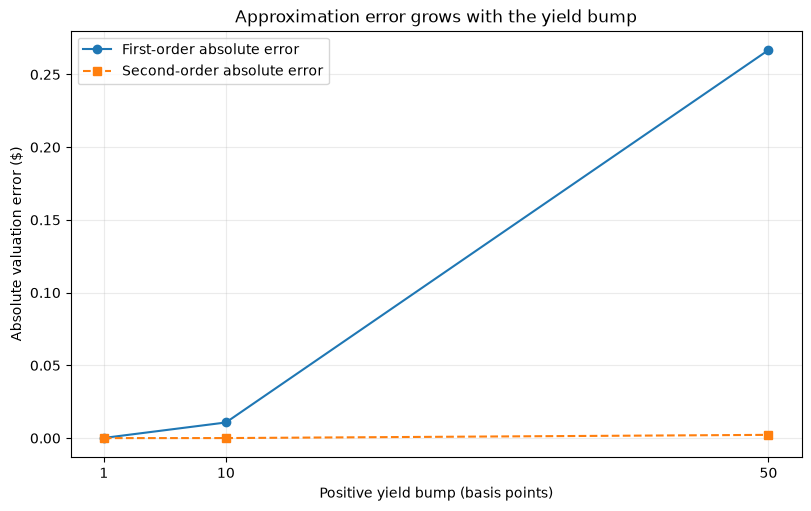

In [4]:
def bond_value(r):
    return 1000 * np.exp(-5 * r)

r0 = 0.03
bump_bps = np.array([1, 10, 50])
delta_r = bump_bps * 1e-4
base_value = bond_value(r0)
first_derivative = -5000 * np.exp(-5 * r0)
second_derivative = 25000 * np.exp(-5 * r0)

full_revaluation = bond_value(r0 + delta_r)
first_order = base_value + first_derivative * delta_r
second_order = first_order + 0.5 * second_derivative * delta_r**2
error_first = np.abs(full_revaluation - first_order)
error_second = np.abs(full_revaluation - second_order)

table = [
    "| Yield bump | Full revaluation | First-order approximation | First-order absolute error | Second-order approximation | Second-order absolute error |",
    "|---:|---:|---:|---:|---:|---:|",
]
for i, bump in enumerate(bump_bps):
    table.append(
        f"| +{bump} bp | {full_revaluation[i]:.6f} | {first_order[i]:.6f} | {error_first[i]:.6f} | "
        f"{second_order[i]:.6f} | {error_second[i]:.6f} |"
    )
display(Markdown("\n".join(table)))

assert np.all(error_second < error_first), "Second-order approximation should be closer for every bump."
assert np.all(np.diff(error_first) > 0), "First-order error should grow with bump size."
assert np.all(np.diff(error_second) > 0), "Second-order error should grow with bump size."

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.plot(bump_bps, error_first, "o-", label="First-order absolute error")
ax.plot(bump_bps, error_second, "s--", label="Second-order absolute error")
ax.set_xlabel("Positive yield bump (basis points)")
ax.set_ylabel("Absolute valuation error ($)")
ax.set_title("Approximation error grows with the yield bump")
ax.set_xticks(bump_bps)
ax.grid(True, alpha=0.25)
ax.legend()
plt.show()